<a href="https://colab.research.google.com/github/deliacovita/ML-Seminar-CovitaDelia/blob/main/Tema_Laborator_3_ML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Temă LP3 — Preprocesarea datelor (Titanic)

**Timp de lucru: maximum 15 minute** · lucru individual

Aplicați tehnicile din LP3 pe un set de date nou: **Titanic** — informații despre pasagerii navei (vârstă, sex, preț bilet, port de îmbarcare, punte) și dacă au supraviețuit (`survived`).

| Sarcina | Tema | Timp |
| --- | --- | --- |
| 1 | Valori lipsă: diagnostic și eliminare pe bază de prag | ~3 min |
| 2 | Imputarea valorilor lipsă | ~3 min |
| 3 | Asimetrie și transformare logaritmică | ~3 min |
| 4 | Outlieri (regula IQR) | ~3 min |
| 5 | Encoding și scalare | ~3 min |

> 💡 Completați celulele marcate `# TODO`. Nu e nevoie de cod perfect — contează să înțelegeți ce face fiecare pas.

### Pregătire — rulați celula (nu necesită modificări)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

titanic = sns.load_dataset('titanic')
df = titanic[['survived', 'pclass', 'sex', 'age', 'fare', 'embarked', 'deck']].copy()
df.head()

,survived,pclass,sex,age,fare,embarked,deck
0,0,3,male,22.0,7.2500,S,NaN
1,1,1,female,38.0,71.2833,C,C
2,1,3,female,26.0,7.9250,S,NaN
3,1,1,female,35.0,53.1000,S,C
4,0,3,male,35.0,8.0500,S,NaN


## Sarcina 1 — Valori lipsă (~3 min)

**1.1** Calculați procentul de valori lipsă pentru fiecare coloană, sortat descrescător.

**1.2** Eliminați coloanele cu **mai mult de 50%** valori lipsă. Care coloană dispare?

In [3]:
# TODO 1.1 — procentul de valori lipsă pe coloană
procent_lipsa = (df.isnull().mean() * 100).sort_values(ascending=False)
print(procent_lipsa)

#calculam media pe fiecare coloana si returnam un tabel pe care il sortam descrescator ca să apară sus coloanele cu cele mai multe valori lipsă

# TODO 1.2 — eliminați coloanele cu > 50% valori lipsă
coloane_de_eliminat = procent_lipsa[procent_lipsa > 50].index
print("Coloane eliminate:", list(coloane_de_eliminat))
df = df.drop(columns=coloane_de_eliminat)
df.head()

#comparam procentul sa vedem daca e mai mult de 50. ".index extrage numele coloanelor care indeplinesc conditia"

age         19.865320
embarked     0.224467
pclass       0.000000
survived     0.000000
sex          0.000000
fare         0.000000
dtype: float64
Coloane eliminate: []


,survived,pclass,sex,age,fare,embarked
0,0,3,male,22.0,7.2500,S
1,1,1,female,38.0,71.2833,C
2,1,3,female,26.0,7.9250,S
3,1,1,female,35.0,53.1000,S
4,0,3,male,35.0,8.0500,S


## Sarcina 2 — Imputarea valorilor lipsă (~3 min)

**2.1** Imputați `age` cu **mediana** și `embarked` cu **valoarea cea mai frecventă** (modul).

**2.2** Verificați că nu mai există valori lipsă și comparați deviația standard a lui `age` înainte și după imputare. *(salvați înainte de imputare: `age_inainte = df['age'].copy()`)*

In [5]:
# TODO 2.1 — imputare age (mediană) și embarked (mod)
age_inainte = df['age'].copy()
#se salveaza o copie a coloanei înainte de imputare ca sa putem compara

mediana_varsta = df['age'].median()
df['age'] = df['age'].fillna(mediana_varsta)
#Înlocuiește fiecare NaN cu 28.0 care e mediana in cazul acesyta

mod_port = df['embarked'].mode()[0]
df['embarked'] = df['embarked'].fillna(mod_port)
#se completeaza cu valorile modului


# TODO 2.2 — verificare + comparație deviație standard
print(df.isnull().sum())
print("Deviația standard înainte:", age_inainte.std())
print("Deviația standard după:  ", df['age'].std())

survived    0
pclass      0
sex         0
age         0
fare        0
embarked    0
dtype: int64
Deviația standard înainte: 13.019696550973194
Deviația standard după:   13.019696550973194


## Sarcina 3 — Asimetrie și transformare logaritmică (~3 min)

**3.1** Calculați skewness-ul variabilei `fare`.

**3.2** Creați coloana `log_fare = np.log1p(fare)` și calculați skewness-ul ei. A ajutat transformarea?

**3.3** Desenați cele două histograme una lângă alta.

Skewness fare: 4.787316519674893
Skewness log_fare: 0.3949280095189306


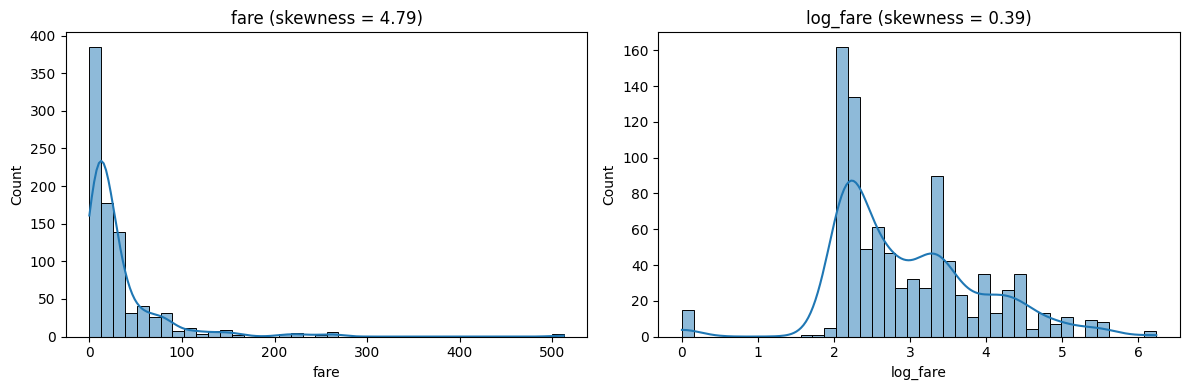

In [7]:
# TODO 3.1 — skewness fare
asimetrie_fare = df['fare'].skew()
print("Skewness fare:", asimetrie_fare)

# TODO 3.2 — coloana log_fare + skewness
df['log_fare'] = np.log1p(df['fare'])
asimetrie_log_fare = df['log_fare'].skew()
print("Skewness log_fare:", asimetrie_log_fare)

#de retinut de ce e log1p si nu log simplu : np.log1p(df['fare']) calculează ln(1 + fare); se folosește log1p în loc de log pentru că în date există bilete cu fare = 0, iar log(0) nu există (dă -inf).

# TODO 3.3 — două histograme
fig, axe = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df['fare'], bins=40, kde=True, ax=axe[0])
axe[0].set_title(f"fare (skewness = {asimetrie_fare:.2f})")

sns.histplot(df['log_fare'], bins=40, kde=True, ax=axe[1])
axe[1].set_title(f"log_fare (skewness = {asimetrie_log_fare:.2f})")

plt.tight_layout()
plt.show()

Skewness fare ≈ 4,79 (foarte asimetric spre dreapta)
Skewness log_fare ≈ 0,40 (aproape simetric)

Raspunsul la 2 este da, pare ca transformarea a ajutat destul de mult in acest caz. Asimetria a scăzut de la ~4,79 la ~0,40, deci distribuția e acum mult mai apropiată de una simetrică.

## Sarcina 4 — Outlieri cu regula IQR (~3 min)

**4.1** Calculați limitele `[Q1 − 1,5·IQR ; Q3 + 1,5·IQR]` pentru `fare` și numărați outlierii.

**4.2** Limitați (clip) valorile extreme într-o coloană nouă, `fare_capped`, și afișați maximul înainte și după.

In [9]:
# TODO 4.1 — limite IQR + număr de outlieri

q1 = df['fare'].quantile(0.25)
q3 = df['fare'].quantile(0.75)
iqr = q3 - q1

limita_inferioara = q1 - 1.5 * iqr
limita_superioara = q3 + 1.5 * iqr

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Limite:", limita_inferioara, "->", limita_superioara)

masca_outlieri = (df['fare'] < limita_inferioara) | (df['fare'] > limita_superioara)
print("Număr de outlieri:", masca_outlieri.sum())

# TODO 4.2 — fare_capped (clip) + maxim înainte/după

fare_inainte = df['fare'].max()
df['fare_capped'] = df['fare'].clip(limita_inferioara, limita_superioara)
fare_dupa = df['fare_capped'].max()

print("Maxim înainte:", fare_inainte)
print("Maxim după:", fare_dupa)

Q1: 7.9104
Q3: 31.0
IQR: 23.0896
Limite: -26.724 -> 65.6344
Număr de outlieri: 116
Maxim înainte: 512.3292
Maxim după: 65.6344


## Sarcina 5 — Encoding și scalare (~3 min)

**5.1** Aplicați One-Hot Encoding pe `sex` și `embarked` (cu `drop_first=True`, `dtype=int`).

**5.2** Standardizați `age` și `fare_capped` cu `StandardScaler`. Verificați că media ≈ 0 și deviația standard ≈ 1.

In [10]:
# TODO 5.1 — One-Hot Encoding pentru sex și embarked
df = pd.get_dummies(df, columns=['sex', 'embarked'], drop_first=True, dtype=int)
print(df.columns.tolist())
df.head()

# TODO 5.2 — StandardScaler pentru age și fare_capped + verificare medie/std
scalator = StandardScaler()
coloane_de_scalat = ['age', 'fare_capped']
df[coloane_de_scalat] = scalator.fit_transform(df[coloane_de_scalat])

print("Media:\n", df[coloane_de_scalat].mean().round(4))
print("Deviația standard:\n", df[coloane_de_scalat].std().round(4))

['survived', 'pclass', 'age', 'fare', 'log_fare', 'fare_capped', 'sex_male', 'embarked_Q', 'embarked_S']
Media:
 age            0.0
fare_capped    0.0
dtype: float64
Deviația standard:
 age            1.0006
fare_capped    1.0006
dtype: float64


Media este 0 si deviatia 1.0006 deoarece StandardScaler împarte la deviația standard calculată cu n la numitor (populație), iar .std() din pandas folosește n − 1 (eșantion)

## Întrebare de reflecție (1–2 propoziții)

*De ce am imputat `age`, dar am eliminat `deck`?*

*Răspunsul tău:* Eu cred ca am imputat age deoarece avea un numar mai mic de valori lipsa undeva la 20%, pe cand deck avea 77% iar aici imputarea nu ar fi mers si nu ar fi fost recomandata deoarece inventam valor si distorsionam datele.